# Qartographer wire routing: a 7 × 7 Xmon wiring demonstrator, a Quantcore-PDK rebuild, step by step

**What the source is.** Qartographer (A. Sural, <https://github.com/AYDOSUL/Qartographer>, MIT, © 2025 Adyoth Sural)
is a cost-function optimiser built on SciPy that places the drive and readout wire paths of a quantum processor,
penalising wires that run too close to each other or too long. It reads and writes JSON. Its shipped example,
`Documentation/7x7 Qubit Placement.json` and `Documentation/7x7 Wiring Data.json`, is a 7 × 7 grid of 49 qubits on a
58 µm pitch (`optimized_qubit_coordinates`, with the 84 nearest-neighbour pairs in `optimized_couplings`), 49 fixed
drive points on an 800 × 1200 µm rectangle round the grid, one optimised drive path per qubit (qubit, a middle point,
its drive point), one multiplexer line through the middle of the grid and a readout tap on it for every qubit. The
map is abstract: it has no component geometry and no frequencies. Spec: `docs/designs/community/qartographer.md`.

**This notebook rebuilds the example as a wiring demonstrator on the Quantcore PDK; it is not a replica.** The map
sets the topology: where the 49 qubits sit, which perimeter point drives which qubit, and between which qubits each
drive path passes. The PDK and the library set the rest.

| | from the source | rebuilt here (why) |
|---|---|---|
| scale | coordinates in metres, 58 µm qubit pitch | one scale for the whole map, × 11.21: a 650 µm qubit pitch; the drive-point rectangle becomes 8.97 × 13.45 mm |
| die | none (the drive points sit on a rectangle) | a 10 × 14.5 mm Quantcore die with the QCT frame (dicing L's, alignment grids); no edge has room for the device ID |
| qubits | 49 points | 49 KQC `Swissmon` Xmons (arms 150 µm, 24 µm wide, 12 µm gap), each with the PDK nominal trilayer junction |
| drive points | 49 fixed points, four of them on the rectangle's corners | 49 `BondPad`s (200 µm pads) on the **PDK pad rule** (`edge="auto"`, 100 µm); the 45 side points keep their place along their edge, the four corner points move onto the left and right edges, 860 µm from the corners (the frame's corner marker areas take the corners) |
| drive paths | qubit, middle point, drive point: straight, no two crossing | one CPW (10 / 6 µm, bends r 50 µm) per path, from the pad through the optimiser's middle point to the Swissmon's drive end; inside the grid each line passes between the same two qubits as the straight path, at the middle of that gap (two lines: ± 50 µm), so it clears the crosses |
| couplings | 84 nearest-neighbour pairs, no coupler geometry | checked against the grid; none drawn: every gap between neighbours can carry a drive line |
| readout | one multiplexer line and 49 taps, no resonators, no frequencies | not built: the 49 straight readout paths cross the drive paths 80 times, and the multiplexer line ends inside the grid with no pad |
| stack, cheese | none | sapphire 650 µm (εr 10.25); the PDK band cheese (`cheese: "auto"`, the source has none) |

**Not reproduced:** the optimiser itself (`Code/Qartographer.py` was not run; this notebook reads its output data) and
its readout network.

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its own
cell with a picture of the chip so far: the die, the 49 drive pads, the 49 Xmons, then the 49 drive lines in three
batches (the outer ring of qubits, the next ring, the core), and the whole chip (the sim groups, the centring check,
the save). Then the same steps as the Flow strip of the Quantcore KLayout plugin: **Check** (DRC, netlist) → **LOM**
(simulation and plots) → **Simulate** (export to HFSS, the component simulation, the eigenmode simulation) →
**Results** (plots, the values, FEM against the LOM, a feedback step and the iteration to a target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. This design was first written as
a segmented notebook, so there is no `.v1` copy beside it.

## Setup

The notebook runs from the repository root. `_common` holds the table, snapshot and PDK helpers shared by the design
notebooks. `LIVE` follows `QCC_LIVE`: with KLayout open, every change below shows up live; with `QCC_LIVE=0` (tests,
batch runs) the snapshots are rendered headless.

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the target.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from collections import Counter
from itertools import combinations
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.circuit.bridges import rn_from_lj

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/community")
OUT.mkdir(parents=True, exist_ok=True)

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the target (Results 5)

## The Quantcore PDK this chip uses

The PDK facts this chip relies on. The library applies each of them: the frame and the cheese in the chip build, the
pad rule through `edge=`, the junctions through `trilayer_junction`, the margins as DRC design warnings.

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | 5 µm squares, 20 µm gaps, ≥ 4 µm from the 3/0 keep-outs: a band of 3 rows around them, or the whole die (`cheese: "chip"`); an original design's own rule or holes where it has them (chip param `cheese`: auto / pdk / chip / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

## The source data

The optimiser's example output, read from the two JSON files (metres, written here in µm):

- `SRC_XY`: `Qubit_k` sits at (677, −95) µm + 58 µm × (k mod 7, k div 7), row by row from the bottom left;
- `DRIVE`: the end of `optimized_drive_paths[k]`, which starts at `Qubit_k`; it is `fixed_drive_points[k]`;
- `MID`: the middle point of that path. In the data it lies on the straight line, at the mean of the two ends (to
  10⁻⁶ µm), so it is computed here;
- `MUX` and `TAP`: `optimized_multiplexer_lines[0]` and, per qubit, its point on that line
  (`optimized_readout_to_multiplexer_lines`), rounded to 0.01 µm;
- `COUPLINGS`: `optimized_couplings`, the 84 nearest-neighbour pairs of the grid (checked below).

The two checks below are what the rebuild relies on: no two straight drive paths cross (so planar lines can follow
them), and the readout taps would cross the drive paths 80 times (so the readout is left out).

In [5]:
# AYDOSUL/Qartographer, Documentation/7x7 Qubit Placement.json + 7x7 Wiring Data.json (MIT, © 2025 Adyoth Sural); µm
SRC_PITCH, SRC_Q0 = 58.0, (677.0, -95.0)
SRC_XY = {k: (SRC_Q0[0] + SRC_PITCH * (k % 7), SRC_Q0[1] + SRC_PITCH * (k // 7)) for k in range(49)}
DRIVE = {0: (450, -500), 1: (516, -700), 2: (716, -700), 3: (850, -700), 4: (1050, -700), 5: (1250, -700),
         6: (1250, -423), 7: (450, -300), 8: (450, -600), 9: (650, -700), 10: (916, -700), 11: (1116, -700),
         12: (1250, -607), 13: (1250, -238), 14: (450, -200), 15: (450, -400), 16: (583, -700), 17: (783, -700),
         18: (1183, -700), 19: (1250, -330), 20: (1250, -146), 21: (450, 0), 22: (450, -100), 23: (450, -700),
         24: (983, -700), 25: (1250, -515), 26: (1250, -53), 27: (1250, 38), 28: (450, 100), 29: (450, 200),
         30: (516, 500), 31: (783, 500), 32: (1183, 500), 33: (1250, 223), 34: (1250, 130), 35: (450, 300),
         36: (450, 400), 37: (650, 500), 38: (916, 500), 39: (1050, 500), 40: (1250, 407), 41: (1250, 315),
         42: (450, 500), 43: (583, 500), 44: (716, 500), 45: (850, 500), 46: (983, 500), 47: (1116, 500),
         48: (1250, 500)}
MID = {k: ((SRC_XY[k][0] + DRIVE[k][0]) / 2, (SRC_XY[k][1] + DRIVE[k][1]) / 2) for k in range(49)}
MUX = ((866.75, -38.14), (830.70, 194.36))
TAP = {0: (866.75, -38.14), 1: (866.75, -38.14), 2: (866.75, -38.14), 3: (866.75, -38.14), 4: (866.75, -38.14),
       5: (866.75, -38.14), 6: (866.75, -38.14), 7: (862.12, -8.30), 8: (863.49, -17.08), 9: (864.85, -25.86),
       10: (866.21, -34.64), 11: (866.75, -38.14), 12: (866.75, -38.14), 13: (866.75, -38.14), 14: (853.34, 48.34),
       15: (854.70, 39.56), 16: (856.07, 30.78), 17: (857.43, 22.00), 18: (858.79, 13.21), 19: (860.15, 4.43),
       20: (861.51, -4.35), 21: (844.56, 104.98), 22: (845.92, 96.20), 23: (847.28, 87.42), 24: (848.65, 78.63),
       25: (850.01, 69.85), 26: (851.37, 61.07), 27: (852.73, 52.29), 28: (835.78, 161.62), 29: (837.14, 152.84),
       30: (838.50, 144.06), 31: (839.86, 135.27), 32: (841.23, 126.49), 33: (842.59, 117.71),
       34: (843.95, 108.93), 35: (830.70, 194.36), 36: (830.70, 194.36), 37: (830.70, 194.36),
       38: (831.08, 191.91), 39: (832.44, 183.13), 40: (833.81, 174.35), 41: (835.17, 165.57),
       42: (830.70, 194.36), 43: (830.70, 194.36), 44: (830.70, 194.36), 45: (830.70, 194.36),
       46: (830.70, 194.36), 47: (830.70, 194.36), 48: (830.70, 194.36)}
COUPLINGS = sorted((a, b) for a in range(49) for b in (a + 1, a + 7)
                   if b < 49 and (b == a + 7 or a // 7 == b // 7))   # optimized_couplings: every grid neighbour pair


def cross(p, q, r, s):
    # where segment p-q crosses segment r-s: (t along p-q, u along r-s), both strictly inside, or None
    d1, d2 = (q[0] - p[0], q[1] - p[1]), (s[0] - r[0], s[1] - r[1])
    den = d1[0] * d2[1] - d1[1] * d2[0]
    if abs(den) < 1e-12:
        return None
    t = ((r[0] - p[0]) * d2[1] - (r[1] - p[1]) * d2[0]) / den
    u = ((r[0] - p[0]) * d1[1] - (r[1] - p[1]) * d1[0]) / den
    return (t, u) if 0 < t < 1 and 0 < u < 1 else None


assert len(COUPLINGS) == 84
n_drive = sum(cross(SRC_XY[a], DRIVE[a], SRC_XY[b], DRIVE[b]) is not None for a, b in combinations(range(49), 2))
n_read = sum(cross(SRC_XY[a], DRIVE[a], SRC_XY[b], TAP[b]) is not None for a in range(49) for b in range(49))
n_mux = sum(cross(SRC_XY[a], DRIVE[a], *MUX) is not None for a in range(49))
print(f"49 qubits, {len(COUPLINGS)} neighbour pairs; straight drive paths crossing each other: {n_drive}; "
      f"drive paths crossing the multiplexer line: {n_mux}; drive paths crossing the readout taps' paths: {n_read}")

49 qubits, 84 neighbour pairs; straight drive paths crossing each other: 0; drive paths crossing the multiplexer line: 0; drive paths crossing the readout taps' paths: 80


## The wiring plan: the map on the die, the pads and the drive-line waypoints

**One scale.** The whole map is scaled by `S` = 650 / 58 ≈ 11.21 about the centre of the drive-point rectangle, which
goes to the centre of the 10 × 14.5 mm die: the qubits land on a 650 µm grid (3.9 mm across), the rectangle on
8.97 × 13.45 mm. The grid sits 2.0 mm above the die centre: in the map it sits 179 µm above the rectangle's
centre.

**Pads.** Each drive point is on one side of the rectangle; its `BondPad` goes on the same die edge, at the same place
along it, and the pad rule (`edge="auto"`) slides it to 100 µm from the edge (its taper tip, port `a`, ends 510 µm
in). The four corner points have no corner pad: the frame's 500 µm marker areas sit in the die corners (600 µm from
each edge with the margin), so these four pads go on the left and right edges, centred 860 µm from the corner, next
to their neighbours in the optimiser's order round the rectangle.

**Waypoints.** A straight drive path from an inner qubit passes as close as 5.4 µm (in the map) to another qubit's
centre: on the die that would cut through a cross. So each path is followed by the gaps it passes through, not by its
exact line. For every gap between two neighbouring qubits, the paths that cross it (at most two) are put at its middle
(two: 50 µm either side of it), in the order the optimiser's paths cross it. A drive line's waypoints, from its pad:
the optimiser's middle point, the gap points (outer first), and an approach point on the diagonal of the quadrant
its path leaves the qubit in. It ends at the Swissmon's drive end (`cl_offset`), 100 µm off both arm axes in that
quadrant, with a 6 µm open gap (`term2`). The 24 qubits of the outer ring cross no gap: their lines leave straight
for the middle point. Keeping the optimiser's order in every gap keeps the lines from crossing inside the grid; the
check below measures the closest two planned lines over their whole length (the DRC checks the built ones).

In [6]:
P = 650.0                                         # qubit pitch on the die (µm)
S = P / SRC_PITCH                                 # one scale for the whole map
W, H = 10000.0, 14500.0                           # the die (µm)
FX0, FY0, FX1, FY1 = 450.0, -700.0, 1250.0, 500.0  # the drive points' rectangle in the map (µm)


def die(x, y):
    # a map point (µm) on the die: scaled by S about the rectangle's centre, which goes to the die centre
    return (W / 2 + S * (x - (FX0 + FX1) / 2), H / 2 + S * (y - (FY0 + FY1) / 2))


QXY = {k: die(*SRC_XY[k]) for k in range(49)}
RING = {k: min(k % 7, k // 7, 6 - k % 7, 6 - k // 7) for k in range(49)}   # 0: the outer ring … 3: the centre

TIP = 100 + 110 + 200 + 100                       # pad_edge + pad_gap + pad_height + taper_length: the tip, from the edge
CORNER = 860.0                                    # a corner point's pad centre, from the die corner (µm)


def corner_point(k):
    return DRIVE[k][0] in (FX0, FX1) and DRIVE[k][1] in (FY0, FY1)


def pad_side(k):
    x, y = DRIVE[k]
    if corner_point(k) or y not in (FY0, FY1):
        return "w" if x == FX0 else "e"
    return "s" if y == FY0 else "n"


def pad_tip(k):
    X, Y = die(*DRIVE[k])
    if corner_point(k):
        Y = CORNER if DRIVE[k][1] == FY0 else H - CORNER
    return {"s": (X, TIP), "n": (X, H - TIP), "w": (TIP, Y), "e": (W - TIP, Y)}[pad_side(k)]


# the gaps (neighbour pairs a-b) each straight path passes through, in order from its qubit; u = where along a -> b
GAP_HITS = {k: sorted((h[0], (a, b), h[1]) for a, b in COUPLINGS
                      if (h := cross(SRC_XY[k], DRIVE[k], SRC_XY[a], SRC_XY[b])) is not None) for k in range(49)}
STREET = 100.0                                    # µm between two lines in one gap
GAP_XY = {}
for a, b in COUPLINGS:
    on = sorted((u, k) for k, hits in GAP_HITS.items() for _, g, u in hits if g == (a, b))
    for j, (_, k) in enumerate(on):
        f = 0.5 + (j - (len(on) - 1) / 2) * STREET / P
        GAP_XY[(k, (a, b))] = (QXY[a][0] + f * (QXY[b][0] - QXY[a][0]), QXY[a][1] + f * (QXY[b][1] - QXY[a][1]))

END, APPROACH = 100.0, 170.0                      # drive end, last waypoint: this far off both arm axes (µm)


def quadrant(k):
    (x, y), (dx, dy) = SRC_XY[k], DRIVE[k]
    return (1 if dx >= x else -1, 1 if dy >= y else -1)


def drive_nodes(k):
    # waypoints of drive line k from its pad: the optimiser's middle point, the gap points (outer first), the approach
    sx, sy = quadrant(k)
    pts = [die(*MID[k])] + [GAP_XY[(k, g)] for _, g, _ in GAP_HITS[k]][::-1]
    pts.append((QXY[k][0] + sx * APPROACH, QXY[k][1] + sy * APPROACH))
    return [(round(x, 3), round(y, 3)) for x, y in pts]


def seg_dist(p, q, r, s):
    # shortest distance between segments p-q and r-s (0 if they cross)
    if cross(p, q, r, s):
        return 0.0

    def to_seg(c, a, b):
        vx, vy = b[0] - a[0], b[1] - a[1]
        t = max(0.0, min(1.0, ((c[0] - a[0]) * vx + (c[1] - a[1]) * vy) / (vx * vx + vy * vy)))
        return math.hypot(a[0] + t * vx - c[0], a[1] + t * vy - c[1])

    return min(to_seg(p, r, s), to_seg(q, r, s), to_seg(r, p, q), to_seg(s, p, q))


PLAN = {k: [pad_tip(k)] + drive_nodes(k) + [(QXY[k][0] + quadrant(k)[0] * END, QXY[k][1] + quadrant(k)[1] * END)]
        for k in range(49)}
closest = min((min(seg_dist(A[i], A[i + 1], B[j], B[j + 1]) for i in range(len(A) - 1) for j in range(len(B) - 1)), a, b)
              for (a, A), (b, B) in combinations(PLAN.items(), 2))
print(f"scale {S:.4f}; qubits x {QXY[0][0]:.1f}…{QXY[48][0]:.1f}, y {QXY[0][1]:.1f}…{QXY[48][1]:.1f} µm")
print("pads per edge:", dict(sorted(Counter(pad_side(k) for k in range(49)).items())),
      "| lines per number of gaps crossed:", dict(sorted(Counter(len(h) for h in GAP_HITS.values()).items())),
      "| most lines in one gap:", max(Counter(g for h in GAP_HITS.values() for _, g, _ in h).values()))
print(f"planned centre lines: the closest two are D{closest[1]} and D{closest[2]}, {closest[0]:.0f} µm apart")

scale 11.2069; qubits x 3061.2…6961.2, y 7306.0…11206.0 µm
pads per edge: {'e': 14, 'n': 11, 's': 11, 'w': 13} | lines per number of gaps crossed: {0: 24, 1: 14, 2: 6, 3: 3, 4: 2} | most lines in one gap: 2
planned centre lines: the closest two are D12 and D25, 89 µm apart


# Design: the layout, one segment at a time

The chip is built the way a designer would lay it out by hand: the die, the bond pads, the readout, the qubits, the
coupling, the control lines, and then the whole chip. Each segment is one cell with one picture of the chip so far
(and, live, KLayout redraws after every cell). Every position comes from the wiring plan above, so the order changes
nothing. With 49 qubits and 49 drive lines the build is kept light: the qubits go in one batch and the lines in three
(`d.batch()` builds once per batch).

| segment | what is placed here |
|---|---|
| 1 | the 10 × 14.5 mm die with its frame |
| 2 | 49 bond pads at the drive points, on the PDK pad rule |
| 3 | nothing: no readout line (the multiplexer line is not built) |
| 4 | the 49 Xmons (`Swissmon`) on the 650 µm grid, with their trilayer junctions and drive ends |
| 5 | nothing: no readout resonators |
| 6 | nothing: no couplers (the 84 neighbour pairs carry no geometry in the source) |
| 7 | the 49 drive lines in three batches: the outer ring (24), the next ring (16), the core (9) |
| 8 | the whole chip: sim groups, the centring check, the save |

## Design 1 · The die and its frame

`Designer(name, box=...)` opens an empty chip. The box is the die (µm); the PDK draws the **QCT frame** on it: L
dicing markers in the four corners (1000/0), a 3 × 3 alignment grid in each corner area (1001/0), the chip boundary
(100/0) and the device ID `name_chip` on a free edge. On the empty die the ID `QART49` sits at the bottom edge; once
the pads fill all four edges (Design 2) the frame finds no room for it and leaves it out (the ID is optional).

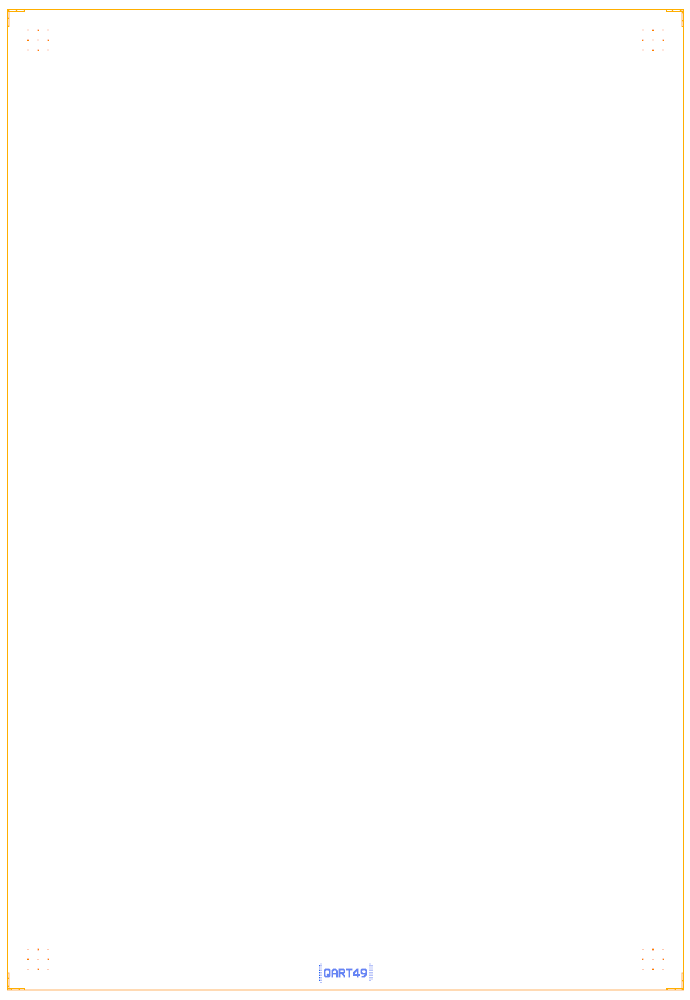

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout.

In [7]:
d = Designer("qartographer", box=(0, 0, W, H), chip={"name_chip": "QART49"}, live=LIVE)
layout_step(d, OUT / "qartographer_die.png", size=(690, 1000), width=300);

## Design 2 · Bond pads: the drive points on the PDK pad rule

One `BondPad` per drive point (pad 200 × 200 µm, 110 µm gap, 100 µm taper), on the die edge of its side of the
rectangle, its port `a` facing into the die. `edge="auto"` slides each pad perpendicular to its nearest edge until the
outer edge of its etch is **`frame.pad_edge` = 100 µm** from the die edge; its place along the edge is the drive
point's. `pads_md(d)` lists each pad's distance.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| P0 | `BondPad` | w | 100.0 | ✓ |
| P1 | `BondPad` | s | 100.0 | ✓ |
| P2 | `BondPad` | s | 100.0 | ✓ |
| P3 | `BondPad` | s | 100.0 | ✓ |
| P4 | `BondPad` | s | 100.0 | ✓ |
| P5 | `BondPad` | e | 100.0 | ✓ |
| P6 | `BondPad` | e | 100.0 | ✓ |
| P7 | `BondPad` | w | 100.0 | ✓ |
| P8 | `BondPad` | w | 100.0 | ✓ |
| P9 | `BondPad` | s | 100.0 | ✓ |
| P10 | `BondPad` | s | 100.0 | ✓ |
| P11 | `BondPad` | s | 100.0 | ✓ |
| P12 | `BondPad` | e | 100.0 | ✓ |
| P13 | `BondPad` | e | 100.0 | ✓ |
| P14 | `BondPad` | w | 100.0 | ✓ |
| P15 | `BondPad` | w | 100.0 | ✓ |
| P16 | `BondPad` | s | 100.0 | ✓ |
| P17 | `BondPad` | s | 100.0 | ✓ |
| P18 | `BondPad` | s | 100.0 | ✓ |
| P19 | `BondPad` | e | 100.0 | ✓ |
| P20 | `BondPad` | e | 100.0 | ✓ |
| P21 | `BondPad` | w | 100.0 | ✓ |
| P22 | `BondPad` | w | 100.0 | ✓ |
| P23 | `BondPad` | w | 100.0 | ✓ |
| P24 | `BondPad` | s | 100.0 | ✓ |
| P25 | `BondPad` | e | 100.0 | ✓ |
| P26 | `BondPad` | e | 100.0 | ✓ |
| P27 | `BondPad` | e | 100.0 | ✓ |
| P28 | `BondPad` | w | 100.0 | ✓ |
| P29 | `BondPad` | w | 100.0 | ✓ |
| P30 | `BondPad` | n | 100.0 | ✓ |
| P31 | `BondPad` | n | 100.0 | ✓ |
| P32 | `BondPad` | n | 100.0 | ✓ |
| P33 | `BondPad` | e | 100.0 | ✓ |
| P34 | `BondPad` | e | 100.0 | ✓ |
| P35 | `BondPad` | w | 100.0 | ✓ |
| P36 | `BondPad` | w | 100.0 | ✓ |
| P37 | `BondPad` | n | 100.0 | ✓ |
| P38 | `BondPad` | n | 100.0 | ✓ |
| P39 | `BondPad` | n | 100.0 | ✓ |
| P40 | `BondPad` | e | 100.0 | ✓ |
| P41 | `BondPad` | e | 100.0 | ✓ |
| P42 | `BondPad` | w | 100.0 | ✓ |
| P43 | `BondPad` | n | 100.0 | ✓ |
| P44 | `BondPad` | n | 100.0 | ✓ |
| P45 | `BondPad` | n | 100.0 | ✓ |
| P46 | `BondPad` | n | 100.0 | ✓ |
| P47 | `BondPad` | n | 100.0 | ✓ |
| P48 | `BondPad` | e | 100.0 | ✓ |

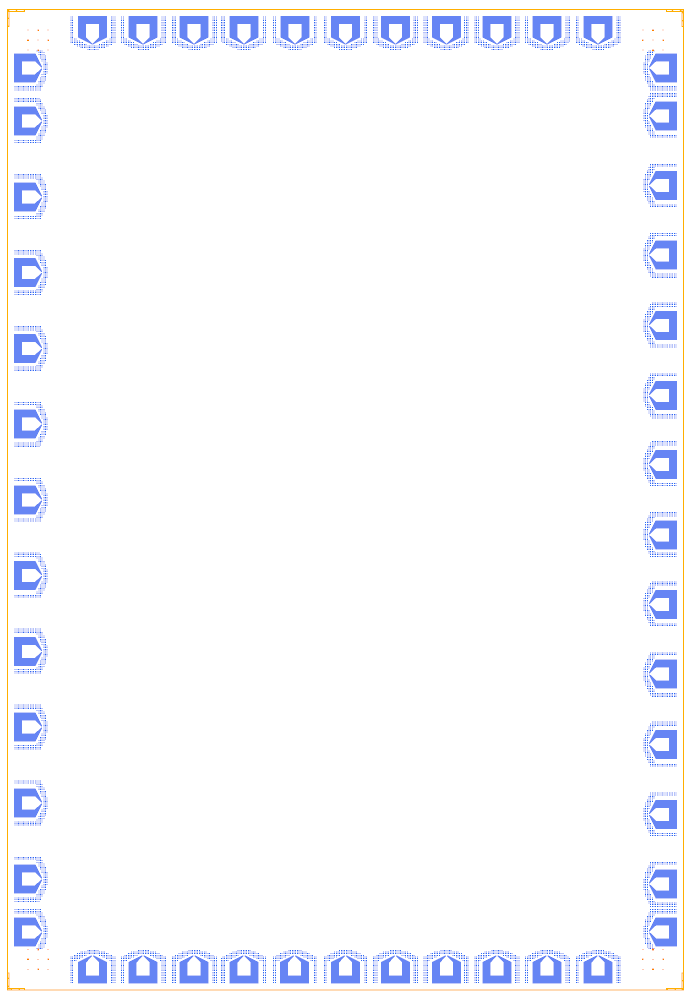

**On the chip so far:** 49 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** 49 component(s) `P0`, `P1`, `P2`, `P3`, `P4`, `P5`, `P6`, `P7` … (+41).

In [8]:
ROT = {"s": 0, "n": 180, "w": -90, "e": 90}       # port a faces into the die
PAD = dict(pad_width=200, pad_height=200, pad_gap=110, taper_length=100)
with d.batch():
    pad = {k: d.add(f"P{k}", "BondPad", at=pad_tip(k), rot=ROT[pad_side(k)], edge="auto", **PAD) for k in range(49)}
rebuild(d)
display(Markdown(pads_md(d)))
layout_step(d, OUT / "qartographer_s2_pads.png", size=(690, 1000), width=300);

## Design 3 · Readout: the line

None. The data's multiplexer line runs 235 µm (in the map) up the middle column of the grid, from beside Q10 to
beside Q38, within 7 µm of the centres of Q17 and Q24, and both its ends are inside the grid, with no drive point or
pad; the straight paths from the qubits to their taps on it would
cross the drive paths 80 times (the source-data check). A planar chip cannot carry both networks without a crossover
per crossing, and the source gives no resonator or frequency for the taps, so this wiring demonstrator leaves the
readout out.

## Design 4 · Qubit placement: 49 Xmons with trilayer junctions

**The junction.** The source has no frequencies, so every qubit gets the PDK nominal junction: `trilayer_junction`
returns the cell parameters of the Quantcore Nb/AlOx/Nb trilayer junction (fingers 0.5 × 0.6 µm on 2/0 + 4/0, the
50/0 spacer with the 51–53/0 dose gradient, R_n 45 kΩ) and the drawn junction's L_J and C_J for the LOM. A single
junction, not a SQUID: the map has drive lines only, no flux lines.

**The qubits.** KQC's `Swissmon`, a grounded Xmon cross with its drive end built in: four 150 µm arms, 24 µm wide, in
a 12 µm gap, the junction below the south arm. The three coupler horseshoes are off (`cpl_length` 0; their ports stay
and end on ground) and there is no flux line. `cl_offset` puts the drive end (port `drive`) 100 µm off both arm axes
in the quadrant the qubit's drive path leaves in, so the line reaches the cross between two arms.

The picture zooms on the grid.

junction: {'junction_type': 'Quantcore Junction'} {'Lj_nH': 6.7344, 'Cj_fF': 15.0} → R_n 45.0 kΩ
drive ends per quadrant (sx, sy): {(-1, -1): 15, (-1, 1): 10, (1, -1): 15, (1, 1): 9}


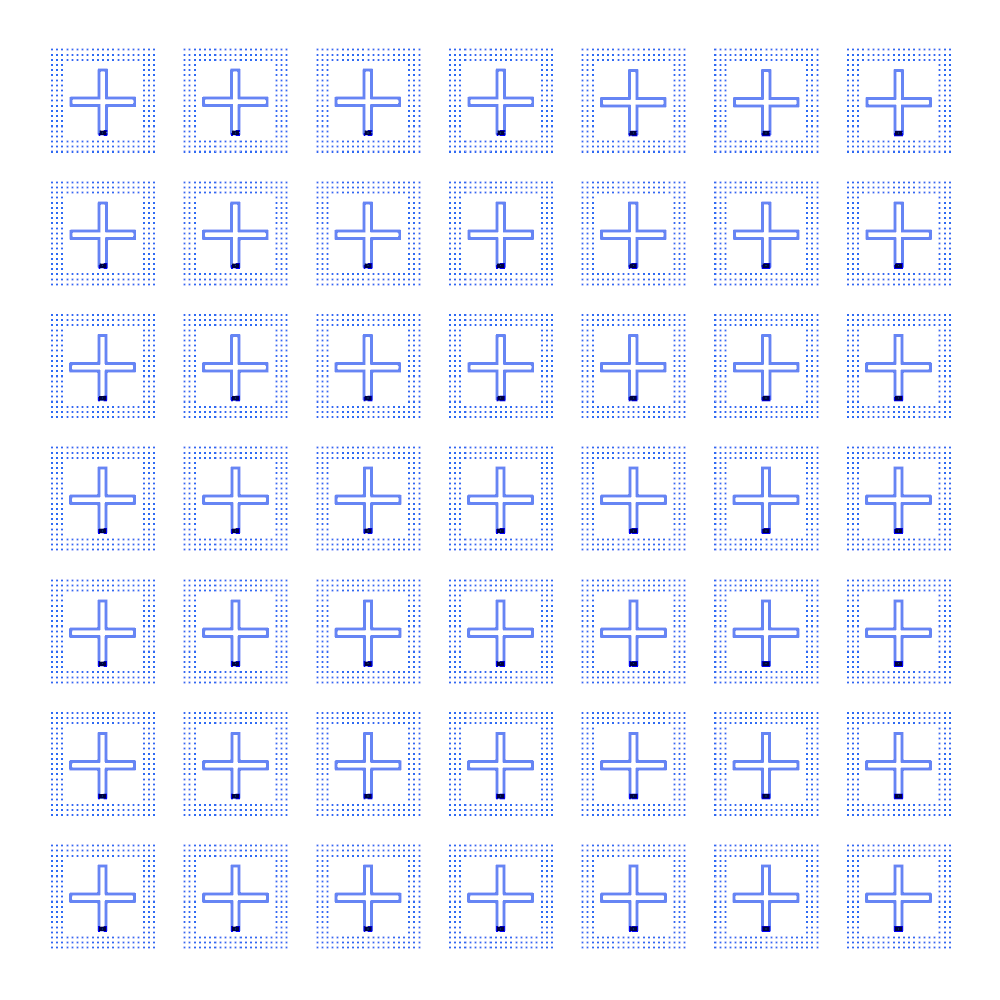

**On the chip so far:** 49 pads · 0 qubits · 49 other components · 0 routes · 0 declared couplings. **This step added** 49 component(s) `Q0`, `Q1`, `Q2`, `Q3`, `Q4`, `Q5`, `Q6`, `Q7` … (+41). KQC's `Swissmon` carries no Quantcore qubit category, so this line counts the 49 qubits among the other components.

In [9]:
JJ_PARAMS, JUNCTION = trilayer_junction("Swissmon")      # PDK nominal: 0.5 × 0.6 µm, R_n 45 kΩ
print("junction:", JJ_PARAMS, JUNCTION, f"→ R_n {rn_from_lj(JUNCTION['Lj_nH']) / 1e3:.1f} kΩ")
XMON = dict(arm_length=[150] * 4, arm_width=[24] * 4, gap_width=[12] * 4, cpl_length=[0, 0, 0], fluxline_type="none")
with d.batch():
    q = {k: d.add(f"Q{k}", "Swissmon", at=QXY[k], junction=JUNCTION, cl_offset=[-quadrant(k)[0] * END,
                  -quadrant(k)[1] * END], **XMON, **JJ_PARAMS) for k in range(49)}
print("drive ends per quadrant (sx, sy):", dict(sorted(Counter(quadrant(k) for k in range(49)).items())))
GRID = (QXY[0][0] - 500, QXY[0][1] - 500, QXY[48][0] + 500, QXY[48][1] + 500)
layout_step(d, OUT / "qartographer_s4_qubits.png", box=GRID, size=(1000, 1000), width=420,
            note="KQC's `Swissmon` carries no Quantcore qubit category, so this line counts the 49 qubits among the "
                 "other components.");

## Design 5 · Readout: the resonators

None: the source has no readout resonators (Design 3).

## Design 6 · Coupling

None drawn. `optimized_couplings` lists the 84 nearest-neighbour pairs of the grid (checked in the source-data cell)
but no coupler geometry, and every gap between two neighbours is where a drive line may pass (up to two per gap), so a
bus or coupler there would cross it. The qubits are independent in this rebuild; the etched ends of neighbouring arms are 326 µm apart.

## Design 7 · Control lines: the drive lines, outer ring first

`d.route(name, pad.a, qubit.drive, nodes=...)` draws a 10 / 6 µm CPW (bends r = 50 µm) from the pad's taper tip
through the planned waypoints to the Swissmon's drive end, where it stops 6 µm short (`term2=6`, an open end). The
first batch is the 24 qubits of the outer ring: their straight paths cross no gap, so the lines run from the drive end
straight through the optimiser's middle point to the pad.

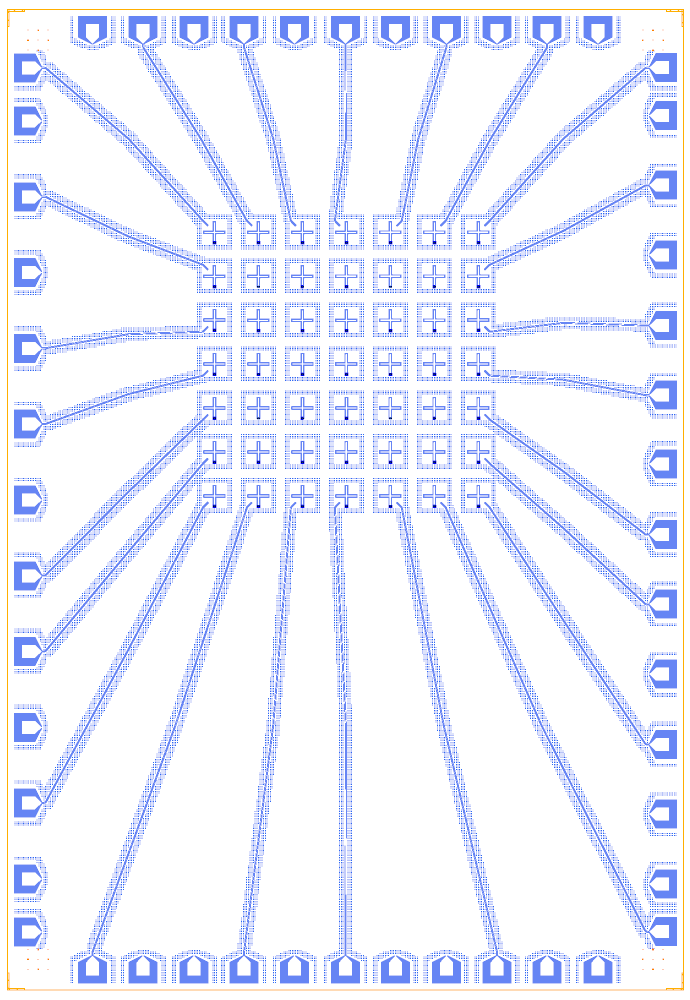

**On the chip so far:** 49 pads · 0 qubits · 49 other components · 24 routes · 0 declared couplings. **This step added** 24 route(s) `D0`, `D1`, `D2`, `D3`, `D4`, `D5`, `D6`, `D7` … (+16).

In [10]:
def drive_line(k):
    return d.route(f"D{k}", pad[k].a, q[k].drive, r=50, term2=6, nodes=drive_nodes(k))


with d.batch():
    for k in (k for k in range(49) if RING[k] == 0):
        drive_line(k)
layout_step(d, OUT / "qartographer_s7a_outer.png", size=(690, 1000), width=300);

**The next ring.** The 16 qubits one row and column in: each line passes through one or two gaps of the outer ring.

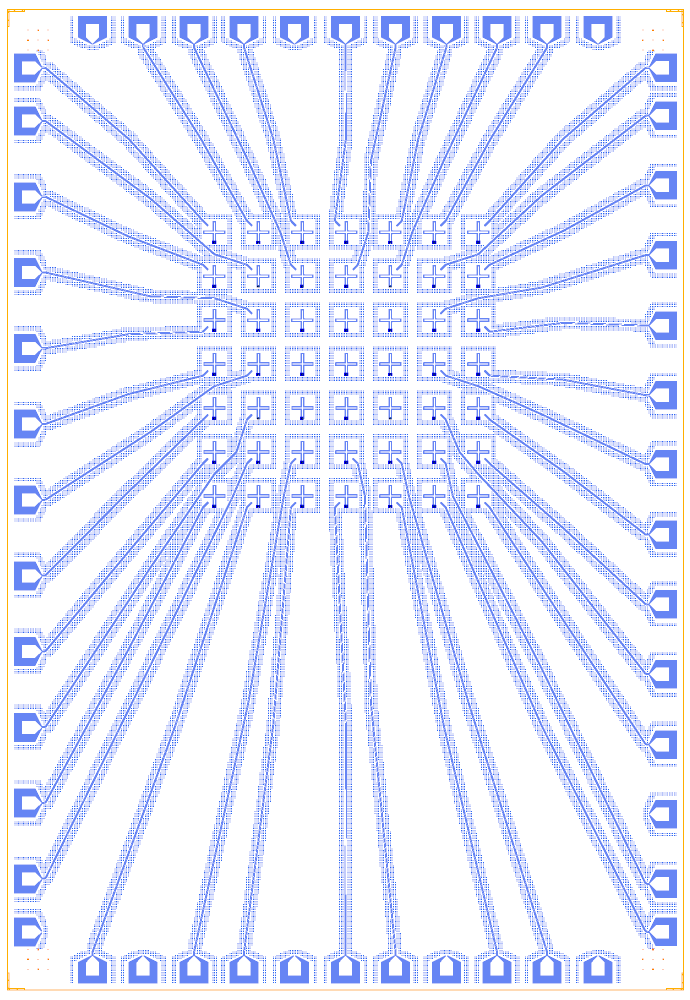

**On the chip so far:** 49 pads · 0 qubits · 49 other components · 40 routes · 0 declared couplings. **This step added** 16 route(s) `D8`, `D9`, `D10`, `D11`, `D12`, `D15`, `D19`, `D22` … (+8).

In [11]:
with d.batch():
    for k in (k for k in range(49) if RING[k] == 1):
        drive_line(k)
layout_step(d, OUT / "qartographer_s7b_ring.png", size=(690, 1000), width=300);

**The core.** The nine inner qubits; their lines pass through up to four gaps (Q23 and Q25). The second picture zooms
on the grid: every line passes between the same two qubits as the optimiser's straight path.

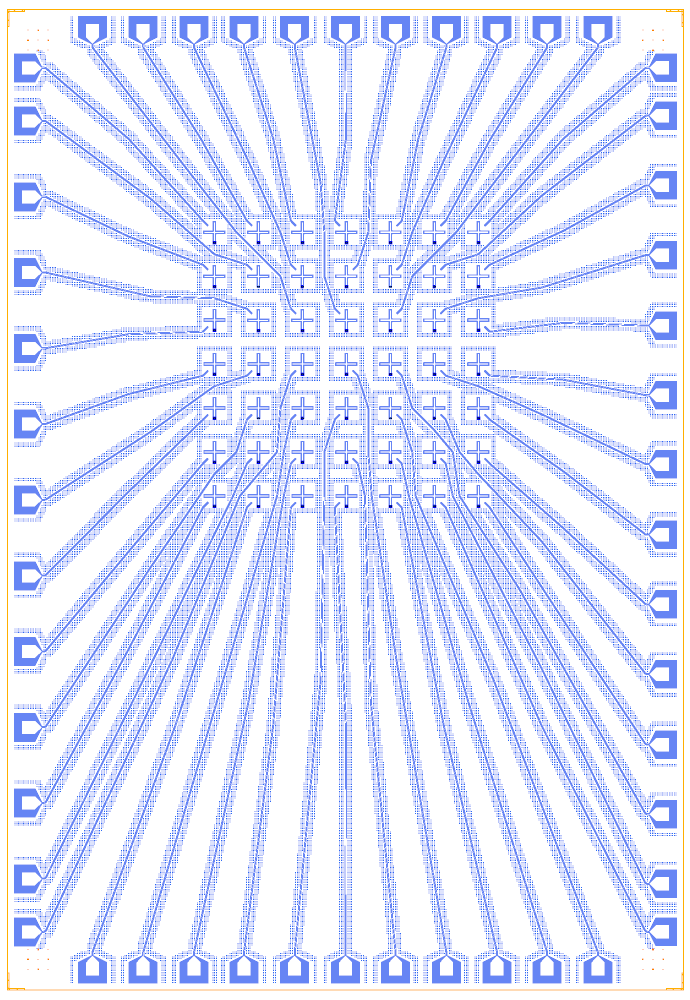

**On the chip so far:** 49 pads · 0 qubits · 49 other components · 49 routes · 0 declared couplings. **This step added** 9 route(s) `D16`, `D17`, `D18`, `D23`, `D24`, `D25`, `D30`, `D31` … (+1).

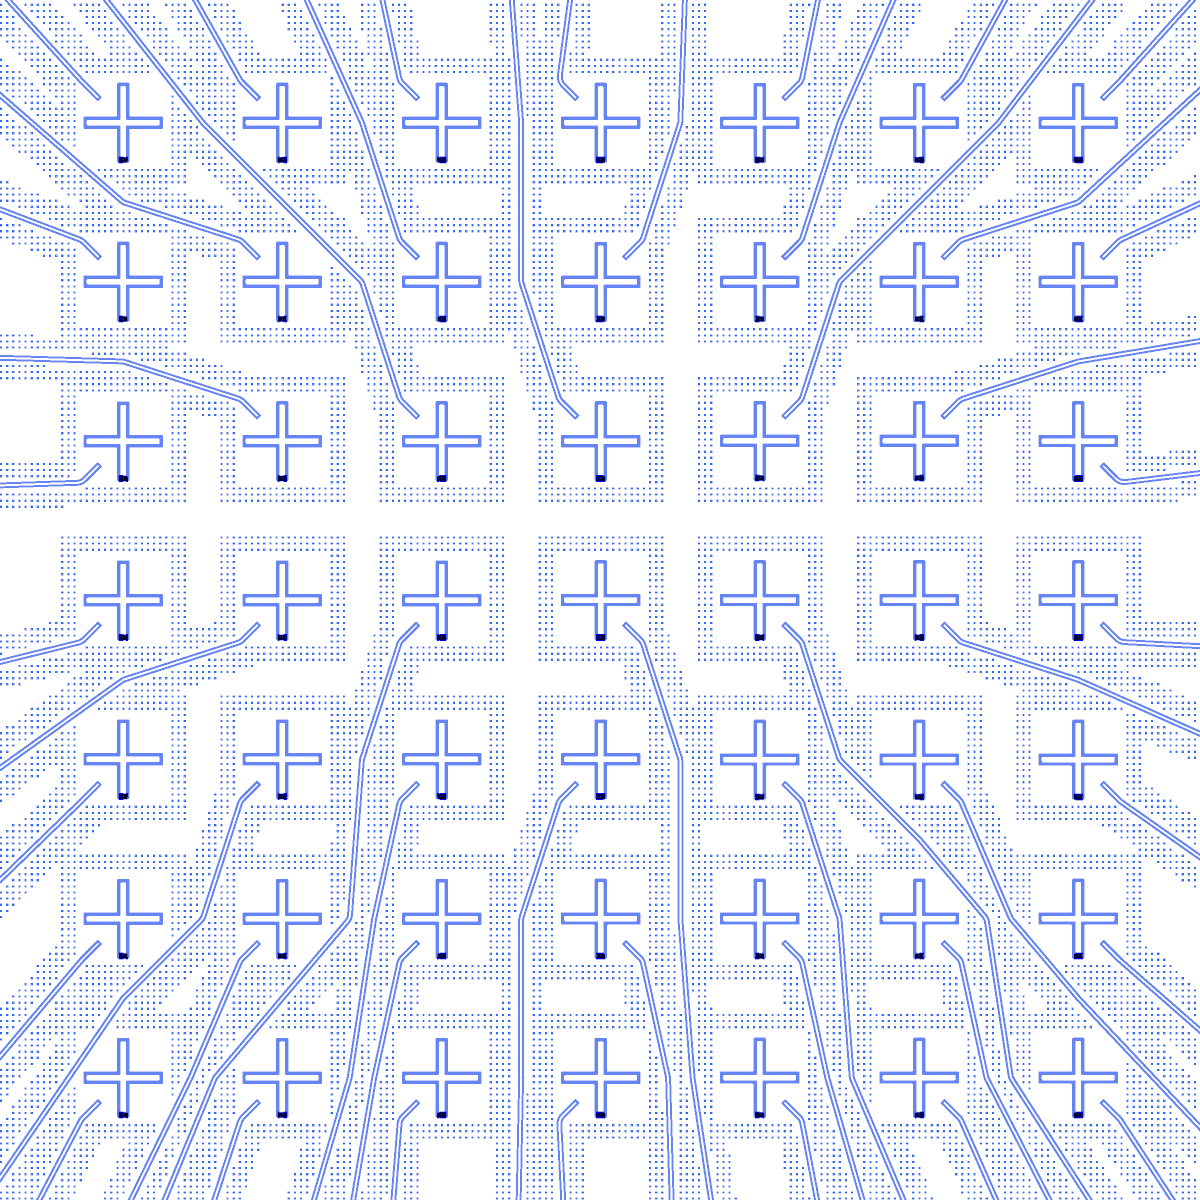

In [12]:
with d.batch():
    for k in (k for k in range(49) if RING[k] >= 2):
        drive_line(k)
layout_step(d, OUT / "qartographer_s7c_core.png", size=(690, 1000), width=300);
snap(d, OUT / "qartographer_grid.png", box=GRID, size=(1200, 1200), width=480);

## Design 8 · The whole chip: sim groups, centring check, save

**Sim groups** say what a FEM job cuts out of the chip: `Q24_drive` is the centre qubit in a box 250 µm beyond its
cross (a Q3D C-matrix and an eigenmode job; the box cuts its drive line `D24`, which becomes a port); `Q17_passing`
is Q17 in the same kind of box, which also cuts `D24` where it passes between Q17 and Q18 (a Q3D C-matrix: the
capacitance between Q17 and a neighbour's drive line, which the LOM leaves out).

**Centring.** `center_in_die(d)` measures the bounding box of everything placed; the pads fill all four edges, so the
content is centred and it returns (0, 0).

**Save.** The JSON is the deliverable. `save_design` writes it and compares it with the file it replaces (the
previous run's): the segments do not change the chip, so a second run says *same design*.

The second picture zooms on Q17: its drive end, and `D24` passing on its right.

centring shift (µm): (0.0, 0.0)


49 drive lines, 2463 to 9208 µm long, 238.2 mm in all


**Same design as before:** `examples/designs/community/qartographer.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer qartographer: 98 instances, 49 routes, live=False> → examples\designs\community\qartographer.json


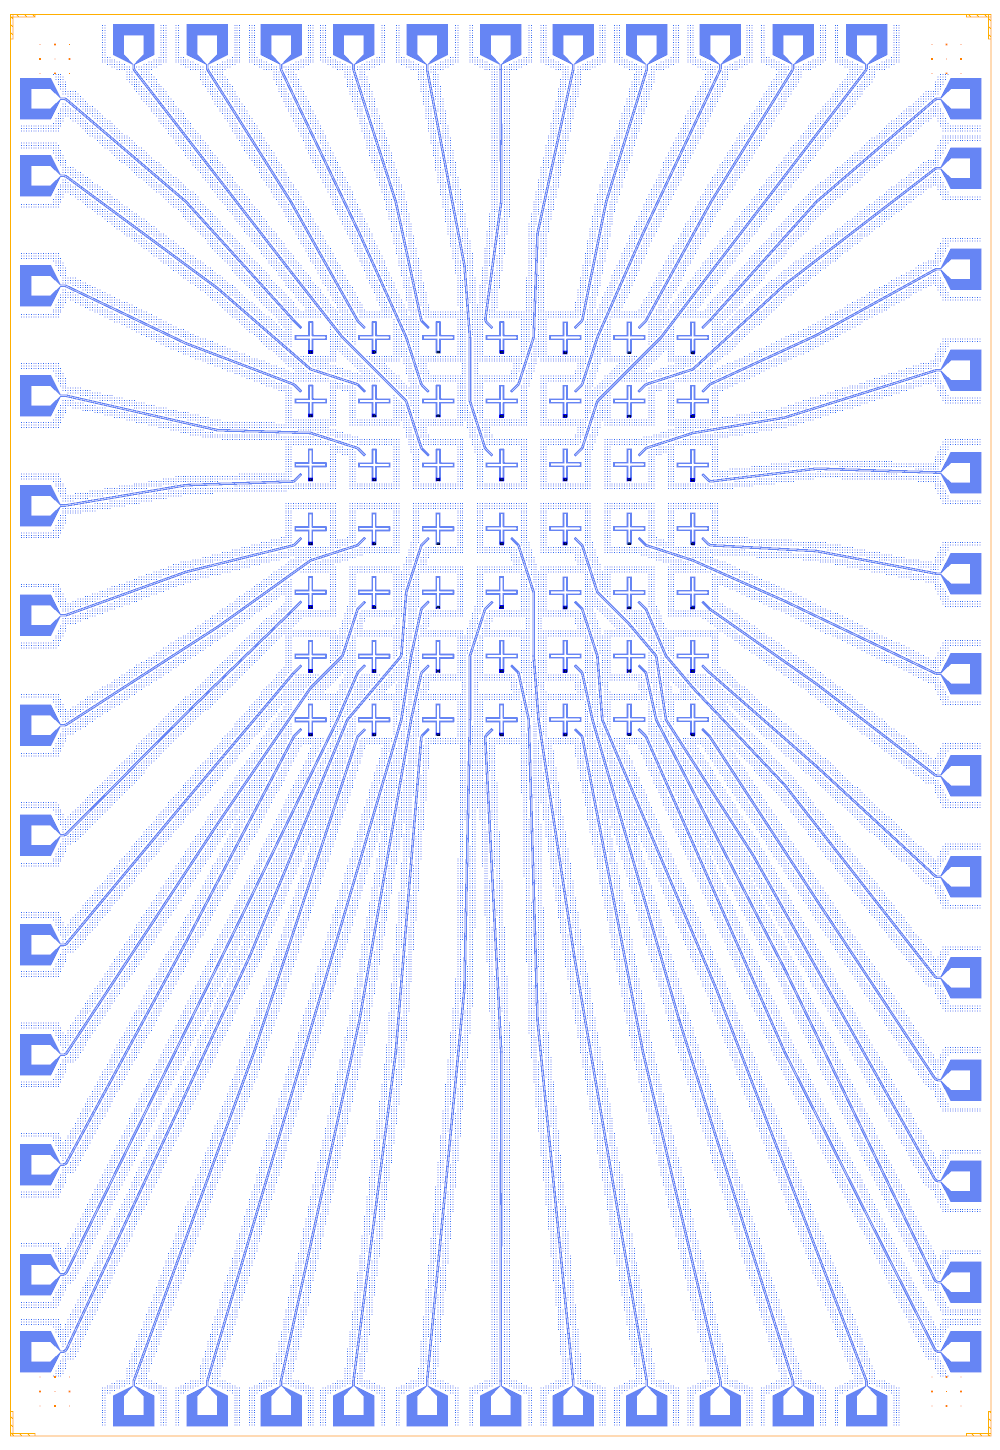

**On the chip so far:** 49 pads · 0 qubits · 49 other components · 49 routes · 0 declared couplings. **This step added** nothing new to the layout.

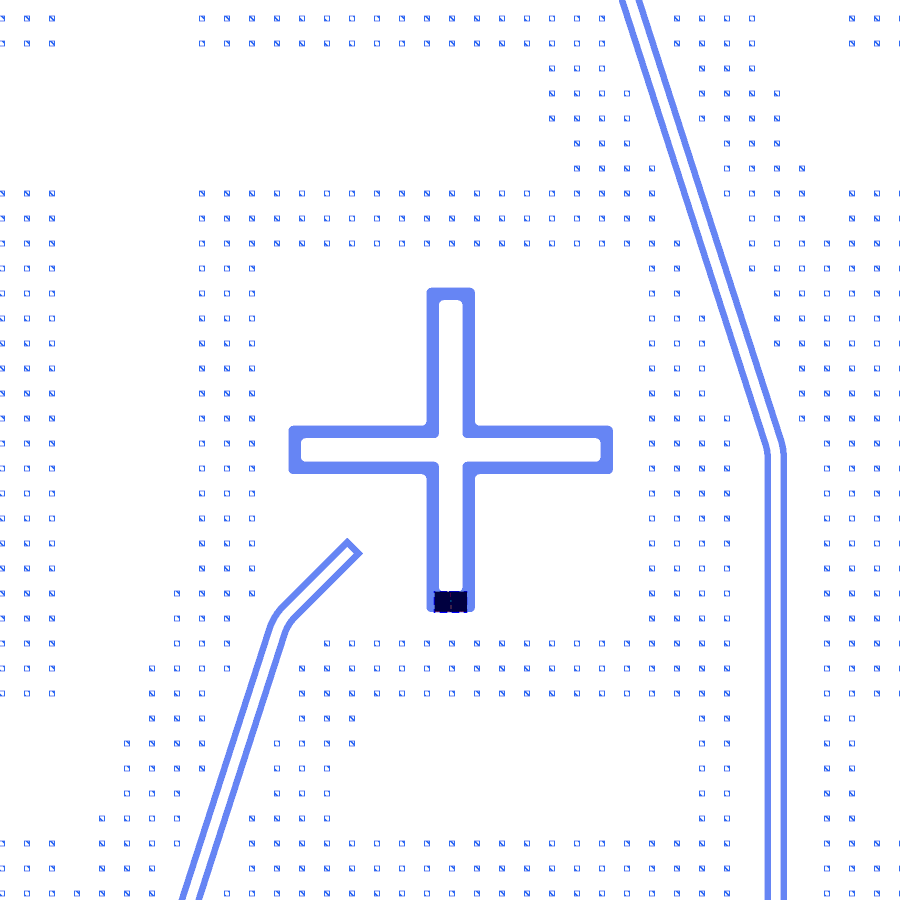

In [13]:
d.sim_group("Q24_drive", ["Q24"], margin_um=250, analyses=["q3d_cmatrix", "eigenmode_epr"])
d.sim_group("Q17_passing", ["Q17"], margin_um=250, analyses=["q3d_cmatrix"])
print("centring shift (µm):", center_in_die(d))
rebuild(d)
L = d.result.route_lengths()
print(f"{len(L)} drive lines, {min(L.values()):.0f} to {max(L.values()):.0f} µm long, {sum(L.values()) / 1e3:.1f} mm in all")
DESIGN, same = save_design(d, OUT / "qartographer.json")
display(Markdown(same))
print(d, "→", DESIGN)
layout_step(d, OUT / "qartographer_s8_chip.png", size=(1000, 1450), width=420);
x17, y17 = QXY[17]
snap(d, OUT / "qartographer_q17.png", box=(x17 - 450, y17 - 450, x17 + 450, y17 + 450), size=(900, 900), width=360);

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC

`d.drc()` checks connectivity (every port routed or snapped, route ends resolved), crossings, overlaps, routes over
components, the chip box and the frame. It has three kinds of findings:
- **errors** (open, short, crossing, a route over a component, outside the chip): the design is broken; there must be
  none;
- **warnings** (an unused port, two component boxes overlapping): worth a look, often by design;
- **PDK design warnings** (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): the design is valid but leaves a PDK margin.
  They are flagged, never fixed by retuning.

Expected: **no errors**; 147 `dangling_port` warnings, the three coupler ports of each Swissmon (`cpl_length` 0: KQC
still declares the ports, the LOM puts them on ground); **no PDK design warnings** (the 49 pads at 100 µm, the
nominal junction in the R_n window, no targets).

In [ ]:
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist

`d.lom()` turns the layout into a lumped circuit: each `Swissmon` is a grounded island (`Q<k>.island`) with its
capacitance and junction to ground; each drive line ends on the qubit's `drive` port, a **drive control**: the line's
conductor keeps its pad's 50 Ω port (`Port_P<k>`) and couples to the island through `Cd_Q<k>`, the library's rough
0.1 fF for an open-ended charge line next to a transmon. The coupler ports end on ground. Whole chip: 49 islands,
49 pad nodes, 196 branches and 49 drive controls. The tables below keep the rows of Q24 and its line (the other 48
qubits look the same).

In [ ]:
lb = d.lom()
md_ = netlist_md(lb)
print(md_.splitlines()[0].strip("*"))
keep = [l for l in md_.splitlines()[1:] if not l.strip() or l.startswith(("| node", "| branch", "| control", "|---"))
        or (l.startswith("|") and any(n in l for n in ("Q24", "P24", "D24")))]
display(Markdown("\n".join(keep)))
print(Counter(b.type for b in lb.model.branches.values()))
print({k: v for k, v in lb.port_map.items() if k.startswith(("Q24.", "P24."))})

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The LOM simulation

Each qubit with its drive line and pad is one group (49 groups, about half a second each): QuCat gives the normal
mode and its κ through the drive line's 50 Ω port, QuTiP the dressed f_q and α. The drive line's κ sets the limit it
puts on T1: T1 ≤ 1 / (2π κ).

**What this LOM can and cannot estimate.** It gives each qubit's f_q and α (the cross and the junction) and the T1
limit from its own drive line. Every qubit has the same cell, the same junction and the same rough drive capacitance,
and a drive line is one conductor node in the LOM (its length and path do not enter), so all 49 groups give the same
numbers. It has nothing to say about the wiring itself: the capacitance between a qubit and the neighbours' lines that
pass it (crosstalk; the `Q17_passing` Q3D job measures it), the coupling between parallel lines, the real drive
capacitance (the `Q24_drive` Q3D job), and the couplings and readout this rebuild does not draw.

The first table sums up the 49 groups, the second lists the seven qubits on the diagonal (corner to corner through
the centre).

In [ ]:
ALL = {f"Q{k}": [f"Q{k}", f"D{k}", f"P{k}"] for k in range(49)}
results = simulate_groups(d, ALL)
VAL = {}
for g, r in results.items():
    m = next(m for m in r.modes if m.kind == "qubit")
    VAL[g] = {"f_q (GHz)": r.params[f"{g}.f_q_GHz"], "α (MHz)": r.params[f"{g}.alpha_MHz"],
              "κ drive (kHz)": 1e3 * m.kappa_MHz, "T1 limit (µs)": 1 / (2 * math.pi * m.kappa_MHz)}
rows = ["| quantity | min | max |", "|---|---|---|"]
for key in VAL["Q0"]:
    vs = [v[key] for v in VAL.values()]
    rows.append(f"| {key} | {min(vs):.4g} | {max(vs):.4g} |")
display(Markdown(f"**{len(VAL)} qubit + drive-line groups:**\n\n" + "\n".join(rows)))
DIAG = [f"Q{8 * i}" for i in range(7)]           # Q0, Q8, …, Q48
display(Markdown(groups_md({g: results[g] for g in DIAG})))
display(Markdown("**Q24, QuCat normal mode:**\n\n" + modes_md(results["Q24"])))

## LOM 2 · The LOM in two plots

The same results as pictures for the seven diagonal qubits: (a) each group's normal mode (QuCat; the filled marker is
the QuTiP dressed f_q), (b) the dispersive shift per resonator, empty here: the chip has no readout. The seven
markers sit at one frequency, as LOM 1 says.

In [ ]:
plot_lom({g: results[g] for g in DIAG}, OUT / "qartographer_lom.png",
         title="qartographer: LOM per qubit + drive line (the diagonal)");

## LOM 3 · One geometry change, by hand

Before the FEM, a design step by hand: copy the saved design (`design_copy`, a non-live Designer that never writes
over the JSON), shorten Q24's four arms from 150 to 130 µm, rebuild and run Q24's group again. Shorter arms have less
capacitance to ground: E_C grows, so f_q and |α| go up. (The copy holds the whole chip, so its LOM build takes a
few seconds.)

In [ ]:
d2 = design_copy(DESIGN)
d2["Q24"].set(arm_length=[130] * 4)
after = simulate_groups(d2, {"Q24": ALL["Q24"]})
display(Markdown(params_delta_md({"Q24": results["Q24"]}, after)))

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS, the component and eigenmode simulations

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates and a rough drive capacitance; a
finite-element job measures them. Each job is a sim group cut out of the chip, written to
`build/jobs/<design>_<group>_<analysis>/`. With `RUN_FEM = False` (the default) the jobs are only exported: the cells
load results that were solved and kept before (in `examples/designs/community/fem/<job>/`), and otherwise say what
would appear.

## Simulate 1 · Export to HFSS

`export_sims` cuts each sim group out of the chip (the box set by `sim_group`), puts ports where lines leave the box
and writes a job folder. Simulation exports never get cheese. Three jobs: the Q3D C-matrices of `Q24_drive` (nets
`Q24.island` and `D24`) and `Q17_passing` (`Q17.island`, its own `D17` and the passing `D24`), and the eigenmode job of
`Q24_drive` (the cut `D24` ends in a 50 Ω lumped port).

`FEM_FAST` (the switch at the top) picks the fast test settings for every job exported from here on. With
`RUN_FEM = True` the next cells solve each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an
AEDT window you have open is never touched. The command-line equivalent is `qcc hfss solve build/jobs/<job>`.

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/community/fem/: solved results are kept here
jobs = export_sims(DESIGN, ["Q24_drive", "Q17_passing"])
jobs_eig = export_sims(DESIGN, ["Q24_drive"], analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

## Simulate 2 · Component simulation: the Q3D C-matrices

`Q24_drive` gives the island's capacitance to ground (C_Σ) and to its own drive line (C_d, the LOM's rough 0.1 fF);
`Q17_passing` gives Q17's capacitance to its own line and to `D24`, the neighbour's line that passes it (the drive
crosstalk). Each net is named after its LOM node, so the matrix goes into the circuit (Results 3). `fem_stage` solves
each job with `RUN_FEM`, else loads its kept results, else says that there are none.

In [ ]:
keep_q3d = fem_stage(jobs, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · q3d": k for g, k in keep_q3d.items()})))
for g, k in keep_q3d.items():
    if k:
        display(Markdown(cmatrix_md(k)))

## Simulate 3 · Eigenmode simulation

The `Q24_drive` box in HFSS eigenmode: the junction is a lumped L_J ‖ C_J sheet and the drive line the box cuts ends
in 50 Ω, so the qubit mode's Q is the loading by its drive line, the T1 limit LOM 1 estimates. pyEPR (run inside
qcc's own AEDT) turns the junction's energy participation into Q24's dressed f_q and α, to compare with the LOM.

In [ ]:
keep_eig = fem_stage(jobs_eig, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · eigenmode": k for g, k in keep_eig.items()})))

## Simulate 4 · Full-wave (driven) run

None. The only line either box cuts is a drive line, so a driven run would give the reflection S11 of one 50 Ω port,
and the qubit's trace in it (κ near 1 kHz) is far below what a fast sweep resolves; the eigenmode's Q gives the
drive-line limit directly.

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step: what the FEM found, against the LOM and against a target, and the design change that
moves the chip towards the target.

## Results 1 · Plot the eigenmodes

(a) each mode's frequency over the adaptive passes (how the mesh converged), (b) the final modes, frequency against
Q, coloured by the junction participation p_J (≈ 1: the qubit), with the LOM's Q24 frequency as a dashed line. The
table below lists the modes and the pyEPR values.

In [ ]:
lom_f = {"Q24": results["Q24"].params.get("Q24.f_q_GHz")}
plot_eigenmodes(keep_eig, OUT / "qartographer_eigenmodes.png", lom=lom_f)
for g, k in keep_eig.items():
    if k:
        display(Markdown(eigen_md(k)))

## Results 2 · The values

The eigenmode job in the LOM's terms: Q24's mode is the one its junction participates in most; f_q is pyEPR's
dressed frequency, α its self-Kerr. There is no readout to read (`epr_values` gets a placeholder readout, and only
Q24's values are kept).

In [ ]:
fem_q = {}
if keep_eig["Q24_drive"]:
    fem_q = {k: v for k, v in epr_values(keep_eig["Q24_drive"], {"Q24": "none"}, {"none": 0.0}).items()
             if k.startswith("Q24.")}
if fem_q:
    display(Markdown("| quantity | FEM |\n|---|---|\n" + "\n".join(f"| `{k}` | {v:.5g} |" for k, v in fem_q.items())))
else:
    print("No eigenmode results yet (RUN_FEM = True): this table would list Q24's f_q and α from pyEPR.")

## Results 3 · FEM against the LOM

**LOM on the Q3D C-matrix:** `fill` replaces the capacitance estimates by the `Q24_drive` job's values (matched by
net name) and Q24's group runs again. **FEM directly:** Q24's eigenmode values (Results 2). The left column is the
LOM on the component estimates (LOM 1). The `Q17_passing` matrix (Simulate 2) has no LOM counterpart: its
Q17 ↔ `D24` entry is the crosstalk capacitance the LOM leaves out.

In [ ]:
from quantcore_circuits.circuit.fill import fill
from quantcore_circuits.lom.simulate import simulate

rows = []
est = results["Q24"].params
if keep_q3d.get("Q24_drive"):
    on_fem = simulate(fill(d.lom(select=ALL["Q24"]).model, DESIGN, keep_q3d["Q24_drive"]), max_modes=2).params
    rows += [(f"Q24: {k}", v, on_fem.get(k), "LOM on the Q24_drive Q3D C-matrix") for k, v in est.items()]
rows += [(k, est.get(k), fem_q[k], "Q24 eigenmode + pyEPR") for k in ("Q24.f_q_GHz", "Q24.alpha_MHz") if k in fem_q]
if rows:
    display(Markdown(fem_vs_lom_md(rows)))
else:
    print("No FEM results yet: with RUN_FEM = True this table puts Q24's f_q and α of the LOM next to the LOM on the "
          "Q3D C-matrix and next to the eigenmode, with the difference in %.")

## Results 4 · Feedback: one step towards a target

The source states no targets, and the 49 qubits are identical, so neighbours sit at one frequency (LOM 1). This
notebook sets one target as an exercise that detunes the centre qubit from its four neighbours: **Q24 at 5.90 GHz**
(dressed), about 0.23 GHz below where the LOM puts it (6.13 GHz). It is reachable inside the PDK junction window: by
the transmon formula Q24's L_J goes from 6.73 nH to about 7.3 nH, R_n about 49 kΩ.

`loop.feedback` tunes qubit–readout pairs, which this chip does not have, so the step is a first-order rule in the
notebook: for a transmon f_q ∝ 1/√L_J, so **L_J ← L_J · (f_now / f_target)²**, kept inside the PDK window
(`pdk_lj_bounds`: R_n 40–50 kΩ). The new L_J is drawn (`trilayer_junction(..., lj_nH=...)` sizes the finger and gives
C_J) on a copy of the design (`design_copy`: the whole chip, so each measurement takes a few seconds). Only L_J moves,
so when the `Q24_drive` Q3D job is kept (Simulate 2) its C-matrix fills every revision's circuit (the FEM point);
otherwise the LOM estimates do. The table shows one step.

In [ ]:
from quantcore_circuits.circuit.fill import fill
from quantcore_circuits.lom.simulate import simulate

Q_T, F_T, TOL = "Q24", 5.90, 0.020               # the exercise target: Q24 at 5.90 GHz ± 20 MHz (dressed)
G_T = ALL[Q_T]                                   # Q24, its drive line and pad (the LOM 1 group)
LO, HI = pdk_lj_bounds(DESIGN)[f"{Q_T}.junction.Lj_nH"]   # the PDK R_n window as L_J bounds (nH)
FEM0 = keep_q3d.get("Q24_drive")                 # a kept Q3D job of the group: its C-matrix holds for every revision


def measure(dd):
    # Q24's dressed f_q (GHz) on design dd: the LOM of the group, filled with the kept group job if any
    return simulate(fill(dd.lom(select=G_T).model, dd.design, FEM0), max_modes=2).params.get(f"{Q_T}.f_q_GHz")


def lj_step(dd, f_now):
    # the feedback rule on dd: L_J <- L_J (f_now / F_T)^2 inside the PDK window; the new junction is drawn
    lj_now = dd.data["instances"][Q_T]["junction"]["Lj_nH"]
    want = lj_now * (f_now / F_T) ** 2
    jp, jj = trilayer_junction("Swissmon", lj_nH=min(max(want, LO), HI))
    dd[Q_T].set(junction=jj, **jp)
    return lj_now, jj["Lj_nH"], not LO <= want <= HI


d_t = design_copy(DESIGN, "_target")             # the revisions are made on this copy; the design file stays
f0 = measure(d_t)
lj0, lj1, clipped = lj_step(d_t, f0)
f1 = measure(d_t)
display(Markdown(before_after_md({"Q24 L_J (nH)": lj0, "Q24 f_q (GHz)": f0},
                                 {"Q24 L_J (nH)": lj1, "Q24 f_q (GHz)": f1})))
print(f"target {F_T} ± {TOL} GHz; one step leaves {1e3 * (f1 - F_T):+.1f} MHz" + (" (L_J at the PDK window's edge)" if clipped else ""))

## Results 5 · Iterate to the target

The feedback step, repeated on a fresh copy: measure → on target (± 20 MHz)? → else the rule again, until on target
or `MAX_ITER` steps. The rule is first order (f_q = √(8 E_J E_C) − E_C, not ∝ 1/√L_J), and the drawn junction moves
on the PDK finger grid, so a step can fall a little short or over and the next one closes the gap. The last revision is
saved (`build/qartographer_target/`) and DRC-checked (a full build of the chip). The table shows each iteration (on:
FEM when the group's C-matrix filled it, else LOM), the plot the residual in tolerances (on target below 1).

In [ ]:
from quantcore_circuits.assembly.drc import check

d_t = design_copy(DESIGN, "_target")             # start again from the design
history, f = [], measure(d_t)
for k in range(MAX_ITER + 1):
    r = None if f is None else (f - F_T) / TOL
    history.append({"iteration": k, "design": Path(DESIGN.name if k == 0 else f"rev{k}"), "fem": FEM0 is not None,
                    "objective": None if r is None else abs(r), "values": {f"{Q_T}.f_q_GHz": f},
                    "targets": {f"{Q_T}.f_q_GHz": (F_T, TOL)}, "on_target": r is not None and abs(r) <= 1,
                    "knobs": {}, "notes": []})
    if history[-1]["on_target"] or r is None or k == MAX_ITER:
        break
    a, b, clipped = lj_step(d_t, f)
    history[-1]["knobs"] = {f"{Q_T}.junction.Lj_nH": (a, b)}
    if clipped:
        history[-1]["notes"].append("L_J at the edge of the PDK window")
    f = measure(d_t)
display(Markdown(history_md(history)))
plot_iterations(history, OUT / "qartographer_iterate.png")
rev = d_t.save(Path("build") / "qartographer_target" / f"rev{history[-1]['iteration']}.json")
print("last design:", rev, "· DRC:", "clean" if check(str(rev)).ok else "ERRORS", "· on target:", history[-1]["on_target"])

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

- **Design file:** `examples/designs/community/qartographer.json` (Design 8); `Designer.load` reopens it.
- **Fab mask:** `export_fab` writes only the PDK fab layers (negative mask: 1/0 etch, 3/0 keep-out, 2/0 + 4/0
  junction fingers, 50–53/0 spacer, 100/0 chip boundary, 1000/0 + 1001/0 frame markers), with corner rounding and the
  cheese the build drew (the PDK band: the source has none).
- **The same from the command line:** `qcc build examples/designs/community/qartographer.json`, `qcc design drc …`,
  `qcc mask …`, `qcc sim build … -g Q24_drive -a q3d_cmatrix`, `qcc hfss solve build/jobs/<job>`.

In [ ]:
rebuild(d)
display(Markdown(fab_layers_md(d, cheese=True, rounding=True)))

## Fab 2 · Snapshots

The full die (49 pads, the fan-out of 49 drive lines into the grid); the grid; the centre qubit Q24 with its drive
end; its trilayer junction below the south arm; the **fab mask** round Q24 (1/0 etch with the PDK band's 5 µm holes
along the 3/0 keep-outs, the junction layers); and the die frame's south-west corner (the dicing L on 1000/0, the
alignment grid on 1001/0, the corner pad P23 above it).

In [ ]:
qx, qy = QXY[24]
snap(d, OUT / "qartographer.png", size=(1000, 1450), width=480)
snap(d, OUT / "qartographer_q24.png", box=(qx - 300, qy - 300, qx + 300, qy + 300), size=(900, 900), width=360)
snap(d, OUT / "qartographer_jj.png", box=(qx - 30, qy - 175, qx + 30, qy - 130), size=(800, 600), width=300)
snap_file(Path("build") / "qartographer_fab.oas", OUT / "qartographer_cheese.png",
          box=(qx - 450, qy - 450, qx + 450, qy + 450), size=(1000, 1000), width=400)
snap(d, OUT / "qartographer_frame.png", box=(0, 0, 1600, 1600), size=(900, 900), width=300);

## Summary

| | |
|---|---|
| matches the source | the 7 × 7 placement (one scale, × 11.21: a 650 µm pitch), the 49 drive points on their edges in the optimiser's order (45 at their own place along the edge), one drive line per path through the optimiser's middle point and the same gaps between qubits as its straight path |
| PDK changes | the 10 × 14.5 mm die with the QCT frame (no room for the device ID); 49 `BondPad`s on the 100 µm pad rule, the four corner points moved onto the side edges; trilayer junctions (PDK nominal); sapphire; the PDK band cheese |
| differs | lines inside the grid go through the middle of each gap (two lines: ± 50 µm) instead of the straight path, which would cut through crosses; the couplings and the readout network are not drawn |
| LOM | every qubit 6.128 GHz dressed (QuCat 6.343), α −225 MHz, drive-line κ 1.35 kHz, so a T1 limit of 118 µs from the rough 0.1 fF drive capacitance; Q24's arms 150 → 130 µm: f_q 6.505 GHz, α −256 MHz (LOM 3) |
| PDK design warnings | none |
| layout | built in segments: die, pads, the 49 Xmons, the drive lines in three batches, the whole chip |
| feedback | an exercise target (Q24 at 5.90 GHz, detuning it from its neighbours) by a first-order L_J rule on Q24's group (no qubit–readout pair for `loop.feedback`); LOM, or FEM capacitances when the group's Q3D job is kept |
| open | the FEM jobs (two Q3D, one eigenmode) are exported, not solved (`RUN_FEM = False`); the crosstalk from passing lines and the real drive capacitance need them |